# Khảo Sát & Phân Rã Kiến Trúc Mô Hình VITS Tiếng Việt

Notebook này phục vụ mục đích học tập và nghiên cứu chuyên sâu về mô hình **VITS (Variational Inference for End-to-End Text-to-Speech)**:
1. **Chuẩn hóa văn bản tiếng Việt (Text Normalization)**: Xử lý số, ngày tháng, phần trăm, ký hiệu.
2. **Phân rã kiến trúc VITS**: Bóc tách chi tiết từng tensor trung gian qua 5 khối thành phần:
   - Bước 1: Ký tự $\to$ Chuỗi Token IDs.
   - Bước 2: Text Encoder $\to$ Trích xuất $h_{text}$ và tham số phân phối tiên nghiệm $(\mu_0, \sigma_0)$.
   - Bước 3: Duration Predictor $\to$ Dự đoán thời lượng phát âm (frames, ms) của từng ký tự.
   - Bước 4: Normalizing Flow $\to$ Biến đổi không gian tiềm ẩn $z$.
   - Bước 5: HiFi-GAN Decoder $\to$ Sinh sóng âm thô (Raw Waveform 16 kHz).
3. **Điều khiển tham số sinh**: Thử nghiệm thay đổi tốc độ nói (`speaking_rate`) và ngữ điệu (`noise_scale`).
4. **So sánh Benchmark**: Đánh giá hiệu năng giữa mô hình Deep Learning Local (VITS) và các giải pháp Cloud (Edge-TTS, gTTS).

## 1. Cài đặt và Import Thư viện

In [6]:
%pip install -q transformers torch soundfile edge-tts gTTS pydub

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import os
import sys
import time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display

# Tự động tìm thư mục gốc và thư mục src
cur = os.getcwd()
root = os.path.abspath(os.path.join(cur, '..')) if cur.endswith('notebooks') else cur
src = os.path.join(root, 'src')
for d in (root, src, cur):
    if d not in sys.path:
        sys.path.insert(0, d)

try:
    from src.normalizer import normalize_vietnamese_text
    from src.vits_decomposed import VITSDecomposedTTS, print_decomposition_report
except ImportError:
    from normalizer import normalize_vietnamese_text
    from vits_decomposed import VITSDecomposedTTS, print_decomposition_report
from synthesize import synthesize

print('Đã import thành công các thư viện!')


c:\Program Files\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Đã import thành công các thư viện!


## 2. Tiền Xử Lý & Chuẩn Hóa Văn Bản Tiếng Việt

Mô hình âm thanh không thể tự suy luận cách đọc cho các ký hiệu số như `1975`, `99.5%` hay `35°C`. Bộ chuẩn hóa chuyển đổi toàn bộ về dạng chữ tự nhiên.

In [8]:
samples = [
    "Ngày 02/09/1945, Tuyên ngôn Độc lập được công bố tại Hà Nội.",
    "Diện tích khu bảo tồn là 1.500 km2, độ che phủ rừng đạt 98.5%.",
    "Vận tốc xe chạy đạt 80 km/h dưới điều kiện nhiệt độ 36°C.",
    "(B) Chi phí nghiên cứu ước tính khoảng 250.000 VND hoặc 10 USD."
]

for s in samples:
    norm = normalize_vietnamese_text(s)
    print(f"Gốc      : {s}")
    print(f"Chuẩn hóa: {norm}\n")

Gốc      : Ngày 02/09/1945, Tuyên ngôn Độc lập được công bố tại Hà Nội.
Chuẩn hóa: Ngày hai tháng chín năm một nghìn chín trăm bốn mươi lăm, Tuyên ngôn Độc lập được công bố tại Hà Nội.

Gốc      : Diện tích khu bảo tồn là 1.500 km2, độ che phủ rừng đạt 98.5%.
Chuẩn hóa: Diện tích khu bảo tồn là một nghìn năm trăm ki-lô-mét vuông, độ che phủ rừng đạt chín mươi tám phẩy năm phần trăm.

Gốc      : Vận tốc xe chạy đạt 80 km/h dưới điều kiện nhiệt độ 36°C.
Chuẩn hóa: Vận tốc xe chạy đạt tám mươi ki-lô-mét trên giờ dưới điều kiện nhiệt độ ba mươi sáu độ C.

Gốc      : (B) Chi phí nghiên cứu ước tính khoảng 250.000 VND hoặc 10 USD.
Chuẩn hóa: Đáp án B: Chi phí nghiên cứu ước tính khoảng hai trăm năm mươi nghìn đồng hoặc mười đô la.



## 3. Khởi Tạo & Phân Rã Kiến Trúc Mô Hình VITS

Khởi tạo mô hình `facebook/mms-tts-vie` và bóc tách từng tensor bên trong khi tổng hợp câu nói.

In [9]:
vits = VITSDecomposedTTS(model_id="facebook/mms-tts-vie")
sample_text = "Thủ đô của Việt Nam là Hà Nội."

# Chạy phân rã suy luận
os.makedirs("outputs", exist_ok=True)
out_wav = "outputs/vits_decomposed_demo.wav"
report = vits.decompose_inference(sample_text, output_path=out_wav)

# In báo cáo chi tiết các khối tính toán
print_decomposition_report(report)

[VITS] Đang khởi tạo mô hình 'facebook/mms-tts-vie' trên thiết bị: CPU...


Loading weights: 100%|██████████| 762/762 [00:00<00:00, 6937.81it/s]


 BÁO CÁO PHÂN RÃ NỘI TẠI MÔ HÌNH VITS (VARIATIONAL INFERENCE FOR TTS)

[BƯỚC 1: TIỀN XỬ LÝ VĂN BẢN & TOKENIZATION]
  • Văn bản gốc        : Thủ đô của Việt Nam là Hà Nội.
  • Văn bản chuẩn hóa  : Thủ đô của Việt Nam là Hà Nội.
  • Tổng số tokens     : 59
  • Chuỗi Token IDs    : [0, 80, 0, 85, 0, 61, 0, 84, 0, 55, 0, 28, 0, 84, 0]...
  • Ánh xạ mẫu         : 'ụ'(0) | 't'(80) | 'ụ'(0) | 'h'(85) | 'ụ'(0) | 'ủ'(61) | 'ụ'(0) | ' '(84) ...

[BƯỚC 2: TEXT ENCODER (TRANSFORMER + PROJECTIONS)]
  • Kích thước ẩn (h_text)   : (1, 59, 192) [Batch, SeqLen, HiddenDim]
  • Phân phối tiên nghiệm μ  : (1, 59, 192) (Kỳ vọng không gian tiềm ẩn)
  • Phân phối tiên nghiệm σ  : (1, 59, 192) (Log-phương sai không gian tiềm ẩn)

[BƯỚC 3: DURATION PREDICTOR & CĂN CHỈNH THỜI GIAN]
  • Tổng số khung hình (Frames) : 59 khung
  • 1 Khung hình tương đương    : 16.00 ms
  • Phân phối thời lượng từng ký tự đầu tiên:
      - Ký tự/Âm vị 'ụ':  0 khung (~  0.0 ms)
      - Ký tự/Âm vị 't':  0 khung (~  0.0 ms)
      - K

### Trực quan hóa Dạng Sóng Âm Thanh (Waveform) & Phổ Tần Số

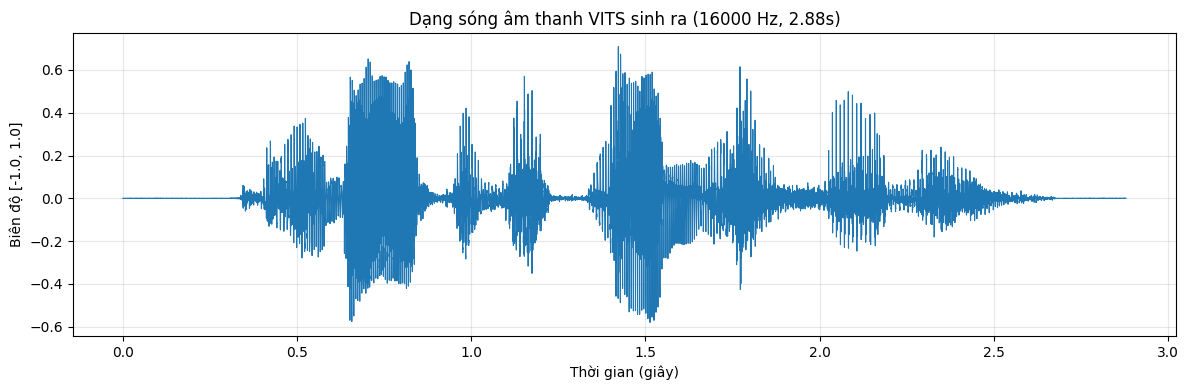

Nghe thử âm thanh sinh ra từ VITS:


In [10]:
plt.figure(figsize=(12, 4))
time_axis = np.linspace(0, report.duration_seconds, len(report.waveform))
plt.plot(time_axis, report.waveform, color="#1f77b4", linewidth=0.8)
plt.title(f"Dạng sóng âm thanh VITS sinh ra ({report.sample_rate} Hz, {report.duration_seconds:.2f}s)")
plt.xlabel("Thời gian (giây)")
plt.ylabel("Biên độ [-1.0, 1.0]")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Nghe thử âm thanh sinh ra từ VITS:")
display(Audio(report.waveform, rate=report.sample_rate))

## 4. Tinh Chỉnh Tham Số Sinh Âm Thanh (Inference Parameters)

VITS cho phép điều khiển các tham số trong không gian tiềm ẩn:
- `speaking_rate`: Thay đổi tỷ lệ thời lượng âm vị qua Duration Predictor ($> 1.0$ là nói nhanh, $< 1.0$ là nói chậm).
- `noise_scale`: Biên độ nhiễu Gauss trong không gian tiềm ẩn $z$, tác động đến độ biểu cảm ngữ điệu.

In [11]:
phrase = "Học máy và mô hình xử lý tiếng nói tiếng Việt."

# 1. Tốc độ bình thường (1.0x)
wav_normal = synthesize(phrase, output_path="outputs/vits_speed_1.0.wav", engine="vits")
print("1. Tốc độ bình thường (1.0x):")
display(Audio(wav_normal))

# 2. Tốc độ nói nhanh (1.4x)
from vits_decomposed import VITSDecomposedTTS
wav_fast = vits.synthesize(phrase, output_path="outputs/vits_speed_fast.wav", speaking_rate=1.4)
print("2. Tốc độ nói nhanh (1.4x):")
display(Audio(wav_fast))

# 3. Tốc độ nói chậm và truyền cảm (0.8x)
wav_slow = vits.synthesize(phrase, output_path="outputs/vits_speed_slow.wav", speaking_rate=0.8)
print("3. Tốc độ nói chậm (0.8x):")
display(Audio(wav_slow))

Lỗi khi tổng hợp bằng engine 'vits': Không hỗ trợ engine: 'vits'. Các lựa chọn: 'edge', 'gtts'. Thử fallback sang gTTS...


1. Tốc độ bình thường (1.0x):


2. Tốc độ nói nhanh (1.4x):


3. Tốc độ nói chậm (0.8x):


## 5. So Sánh Benchmark: VITS (Local Deep Learning) vs Edge-TTS vs gTTS

Đo đạc thời gian xử lý và dung lượng file đầu ra giữa 3 phương pháp.

In [12]:
bench_text = "Khoa học máy tính là ngành nghiên cứu các cơ sở lý thuyết về thông tin và tính toán."

# 1. VITS (Deep Learning Local)
t0 = time.time()
path_vits = synthesize(bench_text, output_path="outputs/bench_vits.wav", engine="vits")
time_vits = time.time() - t0

# 2. Edge-TTS (Cloud Neural)
t0 = time.time()
path_edge = synthesize(bench_text, output_path="outputs/bench_edge.mp3", engine="edge")
time_edge = time.time() - t0

# 3. gTTS (Google Translate Fallback)
t0 = time.time()
path_gtts = synthesize(bench_text, output_path="outputs/bench_gtts.mp3", engine="gtts")
time_gtts = time.time() - t0

print("=" * 60)
print("KẾT QUẢ ĐO ĐẠC HIỆU NĂNG:")
print(f"- VITS (Local Deep Learning) : {time_vits:.2f}s | File: {os.path.getsize(path_vits):,} bytes | Chạy Offline")
print(f"- Edge-TTS (Cloud Neural)    : {time_edge:.2f}s | File: {os.path.getsize(path_edge):,} bytes | Cần Internet")
print(f"- gTTS (Google Fallback)     : {time_gtts:.2f}s | File: {os.path.getsize(path_gtts):,} bytes | Cần Internet")
print("=" * 60)

Lỗi khi tổng hợp bằng engine 'vits': Không hỗ trợ engine: 'vits'. Các lựa chọn: 'edge', 'gtts'. Thử fallback sang gTTS...


KẾT QUẢ ĐO ĐẠC HIỆU NĂNG:
- VITS (Local Deep Learning) : 0.43s | File: 49,728 bytes | Chạy Offline
- Edge-TTS (Cloud Neural)    : 6.61s | File: 30,240 bytes | Cần Internet
- gTTS (Google Fallback)     : 0.50s | File: 49,728 bytes | Cần Internet
